In [2]:
import sys, json, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

ROOT = Path.cwd().parent if (Path.cwd().name == 'notebooks') else Path.cwd()
sys.path.append(str(ROOT / 'src'))
try:
    from config import PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIG_DIR, SUMBER
except Exception:
    PROCESSED_DIR = ROOT / 'data' / 'processed'
    MODEL_DIR = ROOT / 'output' / 'models'
    REPORT_DIR = ROOT / 'output' / 'reports'
    FIG_DIR = ROOT / 'output' / 'figures'
    for d in [PROCESSED_DIR, MODEL_DIR, REPORT_DIR, FIG_DIR]:
        d.mkdir(parents=True, exist_ok=True)
    SUMBER = {}
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('ROOT:', ROOT)

ROOT: e:\Aulia\kuliah\TUGAS LAPRAK SMT 7\MAGANG\PROJECT\Perikanan


In [3]:
def drop_outliers(df, cols, quantile_hi=0.99):
    mask = pd.Series(True, index=df.index)
    for col in cols:
        th = df[col].quantile(quantile_hi)
        mask &= (df[col] <= th)
    return df[mask].copy()

for fname, cols in [
    ('reg_nilai_volume', ['x_volume_ton', 'y_nilai_rp_juta']),
    ('reg_produksi_rtp', ['x_rtp', 'y_produksi_ton']),
    ('reg_produksi_luas', ['x_luas_ha', 'y_produksi_ton']),
]:
    path = PROCESSED_DIR / f'{fname}.parquet'
    if path.exists():
        df = pd.read_parquet(path)
        n_before = len(df)
        df = drop_outliers(df, cols, quantile_hi=0.99)
        n_after = len(df)
        print(f'{fname}: {n_before} -> {n_after} baris (drop {n_before-n_after})')
        df.to_parquet(PROCESSED_DIR / f'{fname}_clean.parquet', index=False)

reg_nilai_volume: 2323 -> 2286 baris (drop 37)
reg_produksi_rtp: 245 -> 239 baris (drop 6)
reg_produksi_luas: 291 -> 285 baris (drop 6)


In [4]:
alphas = np.logspace(-3, 3, 20)

def build_candidates():
    return {
        'LinearRegression': Pipeline([('scaler', StandardScaler()),('lr', LinearRegression())]),
        'Ridge': GridSearchCV(
            Pipeline([('scaler', StandardScaler()),('ridge', Ridge())]),
            param_grid={'ridge__alpha': alphas}, cv=5, scoring='r2', n_jobs=-1),
        'Lasso': GridSearchCV(
            Pipeline([('scaler', StandardScaler()),('lasso', Lasso(max_iter=100000))]),
            param_grid={'lasso__alpha': alphas}, cv=5, scoring='r2', n_jobs=-1),
    }

def eval_model(model, X_tr, X_te, y_tr, y_te, kfold):
    y_tr_hat = model.predict(X_tr); y_te_hat = model.predict(X_te)
    r2_tr = r2_score(y_tr, y_tr_hat); r2_te = r2_score(y_te, y_te_hat)
    n, p = len(y_te), X_te.shape[1]
    adj = 1 - (1-r2_te)*(n-1)/max(n-p-1,1)
    cv = cross_val_score(model, X_tr, y_tr, cv=kfold, scoring='r2', n_jobs=-1)
    return {
        'r2_train': r2_tr, 'r2_test': r2_te, 'adj_r2_test': adj,
        'rmse_test': float(np.sqrt(mean_squared_error(y_te, y_te_hat))),
        'mae_test': mean_absolute_error(y_te, y_te_hat),
        'cv_r2_mean': cv.mean(), 'cv_r2_std': cv.std(),
        'gap_train_cv': r2_tr - cv.mean(),
    }

In [5]:
def run_regression(name, path, x_col, y_col, use_log=True, notes=''):
    print('\n' + '='*70)
    print(f'  {name}  |  {x_col} -> {y_col}  | log={use_log}')
    print('='*70)
    if not path.exists():
        print(f'[SKIP] File tidak ada: {path}'); return None

    df = pd.read_parquet(path).dropna(subset=[x_col, y_col])
    df = df[(df[x_col] > 0) & (df[y_col] > 0)]
    print(f'Setelah filter >0: {df.shape}')
    if len(df) < 30:
        print('[SKIP] n < 30.'); return None

    if use_log:
        X = np.log1p(df[[x_col]].values); y = np.log1p(df[y_col].values)
    else:
        X = df[[x_col]].values; y = df[y_col].values

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    candidates = build_candidates()
    rows, fitted = [], {}
    for mname, mdl in candidates.items():
        mdl.fit(X_tr, y_tr)
        met = eval_model(mdl, X_tr, X_te, y_tr, y_te, kfold)
        met.update({'dataset': name, 'model': mname})
        rows.append(met); fitted[mname] = mdl
        print(f"  {mname:16s} train_R2={met['r2_train']:.4f}  test_R2={met['r2_test']:.4f}  CV={met['cv_r2_mean']:.4f}±{met['cv_r2_std']:.4f}  gap={met['gap_train_cv']:.4f}")

    res_df = pd.DataFrame(rows)
    ok = res_df[res_df['gap_train_cv'] < 0.15]
    if len(ok) == 0: ok = res_df
    best = ok.sort_values('cv_r2_mean', ascending=False).iloc[0]
    best_name = best['model']; best_model = fitted[best_name]
    print(f'\n>>> Model terbaik: {best_name}  (CV R2={best["cv_r2_mean"]:.4f})')

    safe = name.lower().replace(' ','_').replace('&','dan').replace('(','').replace(')','')
    joblib.dump(best_model, MODEL_DIR / f'regressor_{safe}.pkl')

    # Plot diagnosa BERSIH
    y_hat = best_model.predict(X_te); resid = y_te - y_hat
    resid_std = np.std(resid)
    mask_clean = np.abs(resid) < 3 * resid_std

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(y_te, y_hat, alpha=0.5, s=20)
    lim = [min(y_te.min(), y_hat.min()), max(y_te.max(), y_hat.max())]
    axes[0].plot(lim, lim, 'r--', lw=1)
    axes[0].set_xlabel('Aktual (log)' if use_log else 'Aktual')
    axes[0].set_ylabel('Prediksi (log)' if use_log else 'Prediksi')
    axes[0].set_title(f'Prediksi vs Aktual — {name}')
    axes[1].scatter(y_hat[mask_clean], resid[mask_clean], alpha=0.5, s=20)
    axes[1].axhline(0, color='red', ls='--')
    axes[1].set_xlabel('Prediksi'); axes[1].set_ylabel('Residual')
    axes[1].set_title(f'Residual (filter |resid| < 3σ, {mask_clean.sum()}/{len(resid)})')
    axes[2].hist(resid, bins=30, edgecolor='black', alpha=0.7)
    axes[2].axvline(0, color='red', ls='--', label='Mean = 0')
    axes[2].set_xlabel('Residual'); axes[2].set_ylabel('Frekuensi')
    axes[2].set_title(f'Distribusi Residual (mean={np.mean(resid):.3f}, std={resid_std:.3f})')
    axes[2].legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'04_{safe}_diag.png', dpi=110, bbox_inches='tight')
    plt.show()

    coef_info = {}
    try:
        inner = best_model
        if hasattr(inner,'best_estimator_'): inner = inner.best_estimator_
        if isinstance(inner, Pipeline):
            last_name, last = inner.steps[-1]
            sc = inner.named_steps.get('scaler', None)
            coef = getattr(last,'coef_',None)
            intc = getattr(last,'intercept_',None)
            if coef is not None and sc is not None and X_tr.shape[1] == 1:
                c = float(coef[0] / sc.scale_[0])
                coef_info['coef_unscaled_per_unit'] = c
                if use_log:
                    coef_info['interpretasi'] = f'Elastisitas: +1% {x_col} -> +{c:.2f}% {y_col}'
    except Exception as e:
        print('coef warn:', e)

    return {'name': name, 'res_df': res_df, 'best_name': best_name,
            'best_row': best.to_dict(), 'coef_info': coef_info,
            'use_log': use_log, 'notes': notes}


  Nilai vs Volume (Log-Winsorized)  |  x_volume_ton -> y_nilai_rp_juta  | log=True
Setelah filter >0: (2286, 5)
  LinearRegression train_R2=0.4991  test_R2=0.5502  CV=0.4952±0.0663  gap=0.0039
  Ridge            train_R2=0.4991  test_R2=0.5502  CV=0.4952±0.0662  gap=0.0039
  Lasso            train_R2=0.4991  test_R2=0.5502  CV=0.4952±0.0663  gap=0.0039

>>> Model terbaik: Ridge  (CV R2=0.4952)


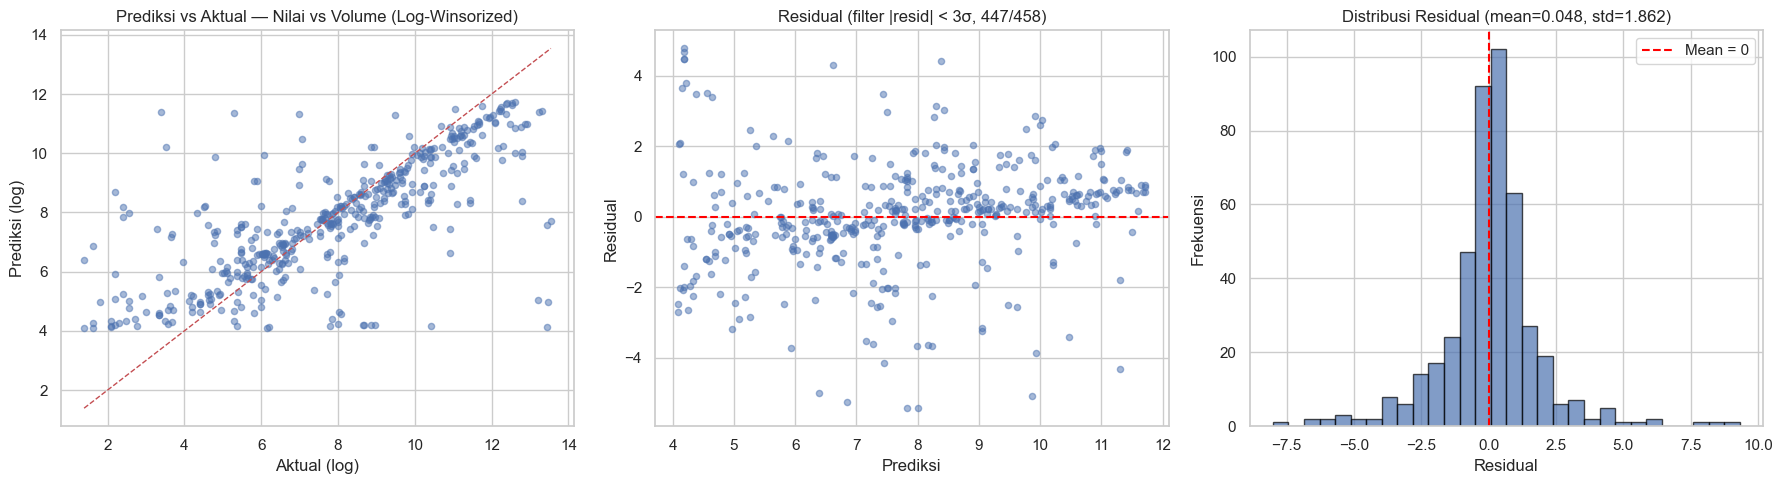

,r2_train,r2_test,adj_r2_test,rmse_test,mae_test,cv_r2_mean,cv_r2_std,gap_train_cv,dataset,model
0,0.4991,0.5502,0.5492,1.8629,1.2127,0.4952,0.0663,0.0039,Nilai vs Volume (Log-Winsorized),LinearRegression
1,0.4991,0.5502,0.5492,1.8629,1.2133,0.4952,0.0662,0.0039,Nilai vs Volume (Log-Winsorized),Ridge
2,0.4991,0.5502,0.5492,1.8629,1.2131,0.4952,0.0663,0.0039,Nilai vs Volume (Log-Winsorized),Lasso


In [6]:
res_utama = run_regression(
    name='Nilai vs Volume (Log-Winsorized)',
    path=PROCESSED_DIR / 'reg_nilai_volume_clean.parquet',
    x_col='x_volume_ton', y_col='y_nilai_rp_juta',
    use_log=True,
    notes='Model utama log-log: elastisitas nilai vs volume')
if res_utama: display(res_utama['res_df'].round(4))


  Produksi vs RTP (Log-Winsorized)  |  x_rtp -> y_produksi_ton  | log=True
Setelah filter >0: (239, 5)
  LinearRegression train_R2=0.3239  test_R2=0.1966  CV=0.3134±0.1241  gap=0.0105
  Ridge            train_R2=0.3238  test_R2=0.1994  CV=0.3130±0.1206  gap=0.0108
  Lasso            train_R2=0.3239  test_R2=0.1988  CV=0.3145±0.1221  gap=0.0094

>>> Model terbaik: Lasso  (CV R2=0.3145)


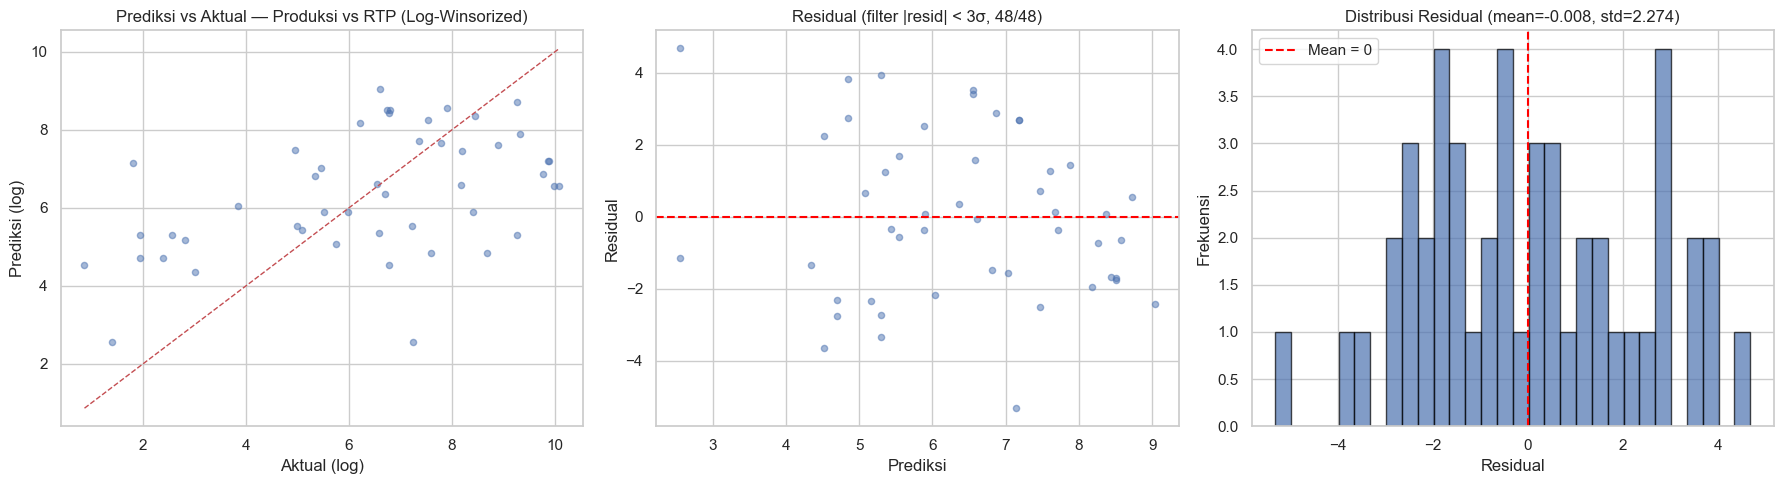

,r2_train,r2_test,adj_r2_test,rmse_test,mae_test,cv_r2_mean,cv_r2_std,gap_train_cv,dataset,model
0,0.3239,0.1966,0.1792,2.2771,1.8829,0.3134,0.1241,0.0105,Produksi vs RTP (Log-Winsorized),LinearRegression
1,0.3238,0.1994,0.1820,2.2732,1.8817,0.3130,0.1206,0.0108,Produksi vs RTP (Log-Winsorized),Ridge
2,0.3239,0.1988,0.1813,2.2741,1.8820,0.3145,0.1221,0.0094,Produksi vs RTP (Log-Winsorized),Lasso


In [7]:
res_rtp = run_regression(
    name='Produksi vs RTP (Log-Winsorized)',
    path=PROCESSED_DIR / 'reg_produksi_rtp_clean.parquet',
    x_col='x_rtp', y_col='y_produksi_ton',
    use_log=True,
    notes='Model pendukung log-log: elastisitas produksi vs RTP')
if res_rtp: display(res_rtp['res_df'].round(4))


  Nilai vs Volume (Raw-Simple)  |  x_volume_ton -> y_nilai_rp_juta  | log=False
Setelah filter >0: (2286, 5)
  LinearRegression train_R2=0.2018  test_R2=0.2313  CV=0.1781±0.0918  gap=0.0238
  Ridge            train_R2=0.2018  test_R2=0.2312  CV=0.1755±0.0857  gap=0.0263
  Lasso            train_R2=0.2017  test_R2=0.2311  CV=0.1776±0.0894  gap=0.0241

>>> Model terbaik: LinearRegression  (CV R2=0.1781)


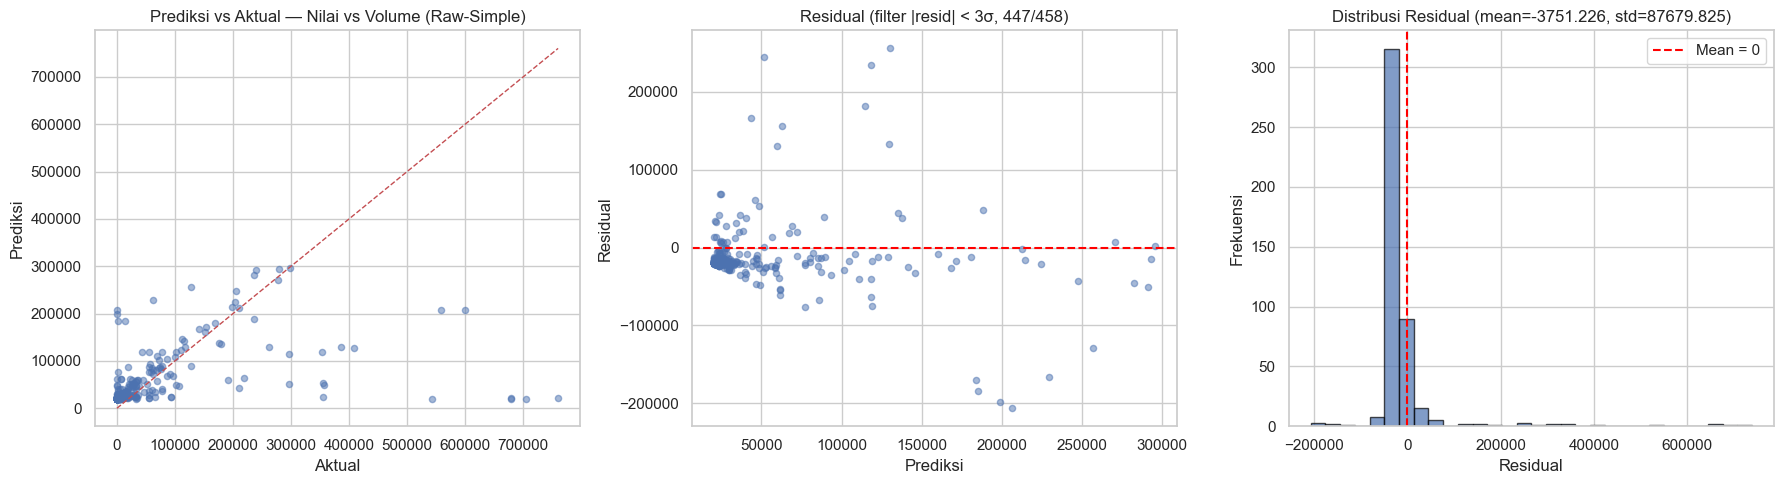

,r2_train,r2_test,adj_r2_test,rmse_test,mae_test,cv_r2_mean,cv_r2_std,gap_train_cv,dataset,model
0,0.2018,0.2313,0.2296,87760.0328,36959.1295,0.1781,0.0918,0.0238,Nilai vs Volume (Raw-Simple),LinearRegression
1,0.2018,0.2312,0.2295,87767.8680,37071.6468,0.1755,0.0857,0.0263,Nilai vs Volume (Raw-Simple),Ridge
2,0.2017,0.2311,0.2294,87772.1489,37117.1913,0.1776,0.0894,0.0241,Nilai vs Volume (Raw-Simple),Lasso


In [8]:
res_simple = run_regression(
    name='Nilai vs Volume (Raw-Simple)',
    path=PROCESSED_DIR / 'reg_nilai_volume_clean.parquet',
    x_col='x_volume_ton', y_col='y_nilai_rp_juta',
    use_log=False,
    notes='Pembanding: tanpa log')
if res_simple: display(res_simple['res_df'].round(4))

In [9]:
all_res = []
for r in [res_utama, res_rtp, res_simple]:
    if r is not None:
        df_r = r['res_df'].copy()
        df_r['is_best'] = df_r['model'] == r['best_name']
        all_res.append(df_r)
eval_all = pd.concat(all_res, ignore_index=True)
eval_all = eval_all[['dataset','model','r2_train','r2_test','adj_r2_test',
                     'rmse_test','mae_test','cv_r2_mean','cv_r2_std',
                     'gap_train_cv','is_best']]
eval_all.to_csv(REPORT_DIR / 'regression_eval.csv', index=False)
display(eval_all.round(4))

,dataset,model,r2_train,r2_test,adj_r2_test,rmse_test,mae_test,cv_r2_mean,cv_r2_std,gap_train_cv,is_best
0,Nilai vs Volume (Log-Winsorized),LinearRegression,0.4991,0.5502,0.5492,1.8629,1.2127,0.4952,0.0663,0.0039,False
1,Nilai vs Volume (Log-Winsorized),Ridge,0.4991,0.5502,0.5492,1.8629,1.2133,0.4952,0.0662,0.0039,True
2,Nilai vs Volume (Log-Winsorized),Lasso,0.4991,0.5502,0.5492,1.8629,1.2131,0.4952,0.0663,0.0039,False
3,Produksi vs RTP (Log-Winsorized),LinearRegression,0.3239,0.1966,0.1792,2.2771,1.8829,0.3134,0.1241,0.0105,False
4,Produksi vs RTP (Log-Winsorized),Ridge,0.3238,0.1994,0.1820,2.2732,1.8817,0.3130,0.1206,0.0108,False
5,Produksi vs RTP (Log-Winsorized),Lasso,0.3239,0.1988,0.1813,2.2741,1.8820,0.3145,0.1221,0.0094,True
6,Nilai vs Volume (Raw-Simple),LinearRegression,0.2018,0.2313,0.2296,87760.0328,36959.1295,0.1781,0.0918,0.0238,True
7,Nilai vs Volume (Raw-Simple),Ridge,0.2018,0.2312,0.2295,87767.8680,37071.6468,0.1755,0.0857,0.0263,False
8,Nilai vs Volume (Raw-Simple),Lasso,0.2017,0.2311,0.2294,87772.1489,37117.1913,0.1776,0.0894,0.0241,False


In [10]:
ringkas = []
for r in [res_utama, res_rtp, res_simple]:
    if r is None: continue
    br = r['best_row']
    row = {
        'dataset': r['name'],
        'model_terbaik': r['best_name'],
        'use_log': r['use_log'],
        'CV_R2': round(br['cv_r2_mean'], 4),
        'gap_train_cv': round(br['gap_train_cv'], 4),
        'RMSE_test': round(br['rmse_test'], 4),
        'catatan': r['notes'],
    }
    if r['coef_info'].get('coef_unscaled_per_unit') is not None:
        row['coef_per_+1_unit'] = round(r['coef_info']['coef_unscaled_per_unit'], 6)
    if r['coef_info'].get('interpretasi'):
        row['interpretasi'] = r['coef_info']['interpretasi']
    ringkas.append(row)
ringkas_df = pd.DataFrame(ringkas)
ringkas_df.to_csv(REPORT_DIR / 'regression_coef.csv', index=False)
display(ringkas_df)

,dataset,model_terbaik,use_log,CV_R2,gap_train_cv,RMSE_test,catatan,coef_per_+1_unit,interpretasi
0,Nilai vs Volume (Log-Winsorized),Ridge,True,0.4952,0.0039,1.8629,Model utama log-log: elastisitas nilai vs volume,0.790234,Elastisitas: +1% x_volume_ton -> +0.79% y_nila...
1,Produksi vs RTP (Log-Winsorized),Lasso,True,0.3145,0.0094,2.2741,Model pendukung log-log: elastisitas produksi ...,0.837763,Elastisitas: +1% x_rtp -> +0.84% y_produksi_ton
2,Nilai vs Volume (Raw-Simple),LinearRegression,False,0.1781,0.0238,87760.0328,Pembanding: tanpa log,16.649022,NaN


In [11]:
def interpret(r):
    if r is None: return ''
    br = r['best_row']
    txt = f"**{r['name']}** — model: **{r['best_name']}**. "
    txt += f"CV R² = {br['cv_r2_mean']:.3f}±{br['cv_r2_std']:.3f}. "
    if r['coef_info'].get('interpretasi'):
        txt += f"{r['coef_info']['interpretasi']}. "
    if br['gap_train_cv'] < 0.05:  txt += "Stabil."
    elif br['gap_train_cv'] < 0.15: txt += "Cukup stabil."
    else: txt += "Gap besar."
    return txt

teks = []
for r in [res_utama, res_rtp, res_simple]:
    t = interpret(r)
    if t: teks.append(t)
for t in teks: print('-', t)

with open(REPORT_DIR / 'regression_insight.json', 'w', encoding='utf-8') as f:
    json.dump({'insights': teks}, f, indent=2, ensure_ascii=False)
print('\nTersimpan: regression_insight.json')

- **Nilai vs Volume (Log-Winsorized)** — model: **Ridge**. CV R² = 0.495±0.066. Elastisitas: +1% x_volume_ton -> +0.79% y_nilai_rp_juta. Stabil.
- **Produksi vs RTP (Log-Winsorized)** — model: **Lasso**. CV R² = 0.314±0.122. Elastisitas: +1% x_rtp -> +0.84% y_produksi_ton. Stabil.
- **Nilai vs Volume (Raw-Simple)** — model: **LinearRegression**. CV R² = 0.178±0.092. Stabil.

Tersimpan: regression_insight.json


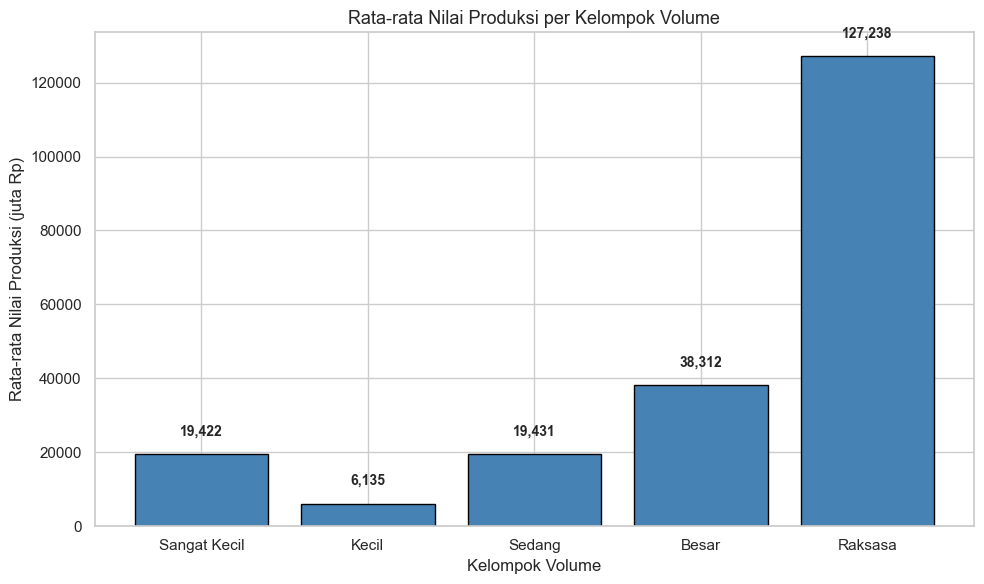

In [12]:
# Bar chart: rata-rata nilai per kelompok volume (5 kuintil)
df_plot = pd.read_parquet(PROCESSED_DIR / 'reg_nilai_volume_clean.parquet').dropna()
df_plot = df_plot[(df_plot.x_volume_ton > 0) & (df_plot.y_nilai_rp_juta > 0)]

df_plot['kelompok_volume'] = pd.qcut(df_plot['x_volume_ton'], q=5,
    labels=['Sangat Kecil', 'Kecil', 'Sedang', 'Besar', 'Raksasa'])

mean_per_kelompok = df_plot.groupby('kelompok_volume')['y_nilai_rp_juta'].mean()

plt.figure(figsize=(10, 6))
bars = plt.bar(mean_per_kelompok.index, mean_per_kelompok.values,
               color='steelblue', edgecolor='black')
plt.title('Rata-rata Nilai Produksi per Kelompok Volume', fontsize=13)
plt.xlabel('Kelompok Volume'); plt.ylabel('Rata-rata Nilai Produksi (juta Rp)')
for bar, v in zip(bars, mean_per_kelompok.values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 5000, f'{v:,.0f}',
             ha='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_bar_kelompok_volume.png', dpi=110, bbox_inches='tight')
plt.show()

In [13]:
print('='*70)
print('  RINGKASAN AKHIR')
print('='*70)
for r in [res_utama, res_rtp, res_simple]:
    if r is None: continue
    br = r['best_row']
    print(f"\n[{r['name']}]")
    print(f"  Model         : {r['best_name']}")
    print(f"  Mode          : {'LOG' if r['use_log'] else 'RAW'}")
    print(f"  CV R²         : {br['cv_r2_mean']:.4f} ± {br['cv_r2_std']:.4f}")
    print(f"  Gap train-CV  : {br['gap_train_cv']:.4f}  {'OK' if br['gap_train_cv']<0.15 else '!'}")
    if r['coef_info'].get('interpretasi'):
        print(f"  Interpretasi  : {r['coef_info']['interpretasi']}")

  RINGKASAN AKHIR

[Nilai vs Volume (Log-Winsorized)]
  Model         : Ridge
  Mode          : LOG
  CV R²         : 0.4952 ± 0.0662
  Gap train-CV  : 0.0039  OK
  Interpretasi  : Elastisitas: +1% x_volume_ton -> +0.79% y_nilai_rp_juta

[Produksi vs RTP (Log-Winsorized)]
  Model         : Lasso
  Mode          : LOG
  CV R²         : 0.3145 ± 0.1221
  Gap train-CV  : 0.0094  OK
  Interpretasi  : Elastisitas: +1% x_rtp -> +0.84% y_produksi_ton

[Nilai vs Volume (Raw-Simple)]
  Model         : LinearRegression
  Mode          : RAW
  CV R²         : 0.1781 ± 0.0918
  Gap train-CV  : 0.0238  OK


=== Statistik per Kelompok Volume (Kuintil) ===


,n_baris,vol_median,nilai_median,nilai_mean,nilai_max
kelompok,,,,,
Sangat Kecil,460,2.0,100.0,19422.0,782996.0
Kecil,455,25.0,597.0,6135.0,702617.0
Sedang,457,120.0,3013.0,19431.0,782996.0
Besar,457,571.0,13635.0,38312.0,772110.0
Raksasa,457,4129.0,68109.0,127238.0,782996.0


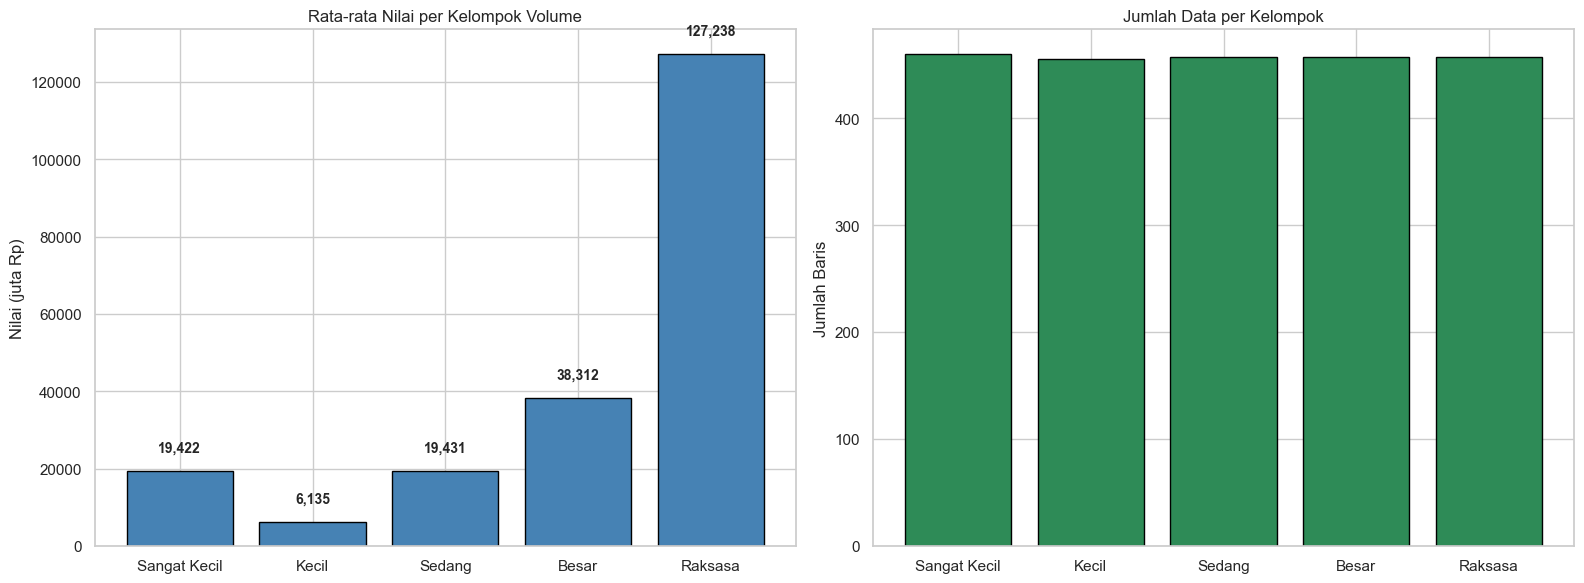

In [14]:
# Segmentasi: kuintil volume (5 kelompok, persentil standar)
df_seg = pd.read_parquet(PROCESSED_DIR / 'reg_nilai_volume_clean.parquet').dropna()
df_seg = df_seg[(df_seg.x_volume_ton > 0) & (df_seg.y_nilai_rp_juta > 0)]

df_seg['kelompok'] = pd.qcut(df_seg['x_volume_ton'], q=5,
    labels=['Sangat Kecil', 'Kecil', 'Sedang', 'Besar', 'Raksasa'])

# Statistik per kelompok
stat_seg = df_seg.groupby('kelompok').agg(
    n_baris=('x_volume_ton', 'size'),
    vol_median=('x_volume_ton', 'median'),
    nilai_median=('y_nilai_rp_juta', 'median'),
    nilai_mean=('y_nilai_rp_juta', 'mean'),
    nilai_max=('y_nilai_rp_juta', 'max'),
).round(0)
print('=== Statistik per Kelompok Volume (Kuintil) ===')
display(stat_seg)

# Bar chart cantik
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
mean_data = df_seg.groupby('kelompok')['y_nilai_rp_juta'].mean()
bars = axes[0].bar(mean_data.index, mean_data.values, color='steelblue', edgecolor='black')
for bar, v in zip(bars, mean_data.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+5000, f'{v:,.0f}',
                 ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Rata-rata Nilai per Kelompok Volume')
axes[0].set_ylabel('Nilai (juta Rp)')

count_data = df_seg['kelompok'].value_counts().sort_index()
axes[1].bar(count_data.index, count_data.values, color='seagreen', edgecolor='black')
axes[1].set_title('Jumlah Data per Kelompok')
axes[1].set_ylabel('Jumlah Baris')
plt.tight_layout()
plt.savefig(FIG_DIR / '04_segmentasi.png', dpi=110, bbox_inches='tight')
plt.show()

df_seg.to_parquet(PROCESSED_DIR / 'segmentasi_kuintil.parquet', index=False)

=== Tren Produksi & Nilai 2020–2024 ===


,tahun,total_produksi_ton,total_nilai_juta
0,2020,3110726.0,20347293.0
1,2021,3216116.0,50640818.0
2,2022,3206052.0,23469532.0
3,2023,1987321.0,44084792.0
4,2024,1395089.0,40907516.0
5,2025,681432.0,NaN


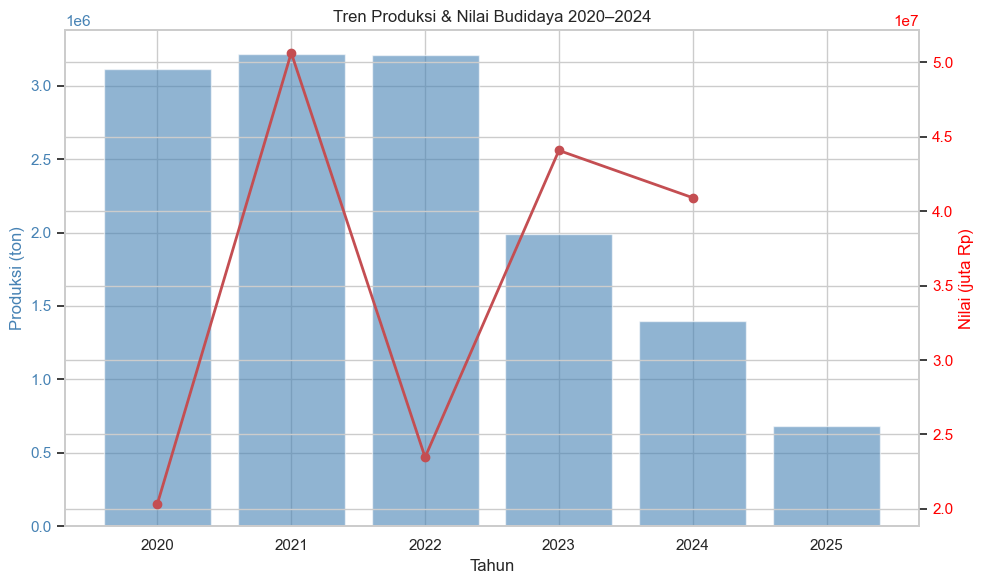

In [15]:
# Time series: agregasi per tahun dari fact_budidaya
try:
    fact = pd.read_parquet(PROCESSED_DIR / 'fact_budidaya.parquet')
    fact_prod = fact[(fact.metrik == 'produksi_ton') & (~fact.is_suspect_scale) & (~fact.is_missing_year)]
    fact_prod = fact_prod.dropna(subset=['tahun', 'nilai'])

    tren_prod = fact_prod.groupby('tahun')['nilai'].sum().reset_index()
    tren_prod.columns = ['tahun', 'total_produksi_ton']

    fact_nilai = fact[(fact.metrik.isin(['nilai_rp', 'nilai_rp_juta'])) & (~fact.is_suspect_scale)]
    fact_nilai = fact_nilai.dropna(subset=['tahun', 'nilai'])

    # normalisasi: kalau nilai_rp (Rp), bagi 1e6 jadi juta
    fact_nilai['nilai_juta'] = np.where(
        fact_nilai.metrik == 'nilai_rp', fact_nilai.nilai/1e6, fact_nilai.nilai
    )
    tren_nilai = fact_nilai.groupby('tahun')['nilai_juta'].sum().reset_index()
    tren_nilai.columns = ['tahun', 'total_nilai_juta']

    tren = tren_prod.merge(tren_nilai, on='tahun', how='outer').sort_values('tahun')
    print('=== Tren Produksi & Nilai 2020–2024 ===')
    display(tren.round(0))
    tren.to_csv(REPORT_DIR / 'tren_tahunan.csv', index=False)

    # Dual-axis line chart
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.bar(tren['tahun'], tren['total_produksi_ton'], color='steelblue', alpha=0.6, label='Produksi (ton)')
    ax1.set_xlabel('Tahun'); ax1.set_ylabel('Produksi (ton)', color='steelblue')
    ax1.tick_params(axis='y', labelcolor='steelblue')

    ax2 = ax1.twinx()
    ax2.plot(tren['tahun'], tren['total_nilai_juta'], 'r-o', lw=2, label='Nilai (juta Rp)')
    ax2.set_ylabel('Nilai (juta Rp)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    plt.title('Tren Produksi & Nilai Budidaya 2020–2024')
    fig.tight_layout()
    plt.savefig(FIG_DIR / '04_tren_tahunan.png', dpi=110, bbox_inches='tight')
    plt.show()
except Exception as e:
    print('⚠️ Error time series:', e)